# Reduction of DL3 runs to map datasets

`uuls.reduce.from_dl3` turns a DL3 folder into the reduced datasets of the analysis: per run a `MapDataset`
(counts, background, exposure, PSF, energy dispersion, offset-max safe mask), a ring background estimate as
in the reference analysis (Berge et al. 2007; r_in 0.3 deg, width 0.2 deg), the stack of all runs, and the
GTIs of each run in seconds since the merger. The same call works on real and simulated DL3; here it runs on
the two simulations of `03_simulated_data` (four 20-minute wobble runs, background only and with a
1e-11 cm-2 s-1 TeV-1, index 2 source at the centre).

Checks: the background-only significance map should be distributed close to N(0, 1), and a fit of a point
source to the stacked dataset should recover the injected flux.

Inputs: `outputs/results/0_tools/03_simulated_data/pointings.ecsv` and `simulation.json`; cache entries
`simulst_dl3/<key>` (from 03) and `reduce/<key>`, printed below.

Outputs: figures in `outputs/figures/0_tools/04_reduce/`.

In [1]:
import json

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord
from astropy.table import Table
from astropy.time import Time
from gammapy.estimators import ExcessMapEstimator
from gammapy.modeling import Fit
from gammapy.modeling.models import PointSpatialModel, PowerLawSpectralModel, SkyModel
from scipy import stats

from uuls import paths, pointings, reduce, simdata
from uuls.figures import FigureSaver

figs = FigureSaver("0_tools", "04_reduce")
inputs = paths.RESULTS / "0_tools" / "03_simulated_data"

The pointings and simulation settings of notebook 03. `simulate` with the same arguments returns the cached
DL3 folders.

In [2]:
point = pointings.read(inputs / "pointings.ecsv")
T0 = Time(point.meta["t0"], scale="utc")
sim = json.loads((inputs / "simulation.json").read_text())
TARGET = SkyCoord(*sim["target"], unit="deg")
SOURCE = simdata.PowerLawSource(**sim["source"])
dl3_bkg = simdata.simulate(point, nsb=sim["nsb"], seed=sim["seed"], production=sim["production"])
dl3_src = simdata.simulate(point, nsb=sim["nsb"], seed=sim["seed"], source=SOURCE, production=sim["production"])
print(f"merger time {T0.isot}, {len(point)} runs, production {sim['production']}, source {SOURCE}")

[cache] simulst_dl3/33cf7015fe2d: loaded (4 runs)
[cache] simulst_dl3/5693826d6bc6: loaded (4 runs)
merger time 2025-10-20T20:30:00.000, 4 runs, production 2025_2p5, source PowerLawSource(ra=7.53, dec=45.81, amplitude=1e-11, index=2.0)


The analysis geometry of the reference: centred on the target, 3.575 deg wide (2.5 deg x 1.43), 0.08 deg
pixels, AIR projection, reconstructed energy 0.6-20 TeV at 4.5 bins per decade. The true-energy axis
(0.05-100 TeV) and the background settings are in `reduce.DEFAULT_SETTINGS`.

In [3]:
geom = reduce.analysis_geom(TARGET)
print(geom)
print("reco energy edges [TeV]:", np.round(geom.axes["energy"].edges.to_value(u.TeV), 3))
reduce.DEFAULT_SETTINGS

WcsGeom

	axes       : ['lon', 'lat', 'energy']
	shape      : (np.int64(45), np.int64(45), 7)
	ndim       : 3
	frame      : icrs
	projection : AIR
	center     : 7.5 deg, 45.8 deg
	width      : 3.6 deg x 3.6 deg
	wcs ref    : 7.5 deg, 45.8 deg

reco energy edges [TeV]: [ 0.6    0.99   1.634  2.697  4.45   7.344 12.119 20.   ]


{'e_true_tev': [0.05, 100.0],
 'true_bins_per_decade': 4.5,
 'offset_max_deg': 2.5,
 'safe_mask': ['offset-max'],
 'background': 'ring',
 'ring_r_in_deg': 0.3,
 'ring_width_deg': 0.2,
 'ring_within_safe_mask': True,
 'exclusion': [],
 'obs_ids': None,
 'bkg_pattern': None,
 'correlation_radius_deg': 0.1}

Both simulations reduced with the reference settings (ring background).

In [4]:
red_bkg = reduce.from_dl3(dl3_bkg, geom, T0)
red_src = reduce.from_dl3(dl3_src, geom, T0)
print(red_src.stacked)

[cache] reduce/888c30ce41f3: computed and stored


[cache] reduce/9543d085a43e: computed and stored
MapDataset
----------

  Name                            : stacked 

  Total counts                    : 5214 
  Total background counts         : 5203.66
  Total excess counts             : 10.34

  Predicted counts                : 5203.66
  Predicted background counts     : 5203.66
  Predicted excess counts         : nan

  Exposure min                    : 1.71e+04 m2 s
  Exposure max                    : 1.70e+09 m2 s

  Number of total bins            : 14175 
  Number of fit bins              : 14175 

  Fit statistic type              : cash
  Fit statistic value (-2 log(L)) : nan

  Number of models                : 0 
  Number of parameters            : 0
  Number of free parameters       : 0




Per run: the GTI in hours after the merger, the livetime, and the counts and ring background inside the safe
mask, summed over energy.

In [5]:
def in_mask(ds, m):
    sel = ds.mask_safe.data
    return float(m.data[sel].sum())


livetime = dict(zip(simdata.run_summary(dl3_src)["obs_id"], simdata.run_summary(dl3_src)["LIVETIME"]))
rows = []
for obs_id, ds, gti in zip(red_src.obs_ids, red_src.runs, red_src.run_gti_s):
    rows.append({"run": ds.name, "start [h]": gti[0, 0] / 3600, "stop [h]": gti[-1, 1] / 3600,
                 "livetime [min]": livetime[obs_id] / 60,
                 "counts": in_mask(ds, ds.counts), "background": in_mask(ds, ds.npred_background())})
Table(rows=rows)

run,start [h],stop [h],livetime [min],counts,background
str4,float64,float64,float64,float64,float64
run1,1.1666666666666679,1.5,19.027199999999933,1593.0,1584.0130615234375
run2,1.5,1.8333333333333348,18.99627999999993,1433.0,1435.19091796875
run3,1.8333333333333348,2.166666666666667,18.96979999999993,857.0,856.6040649414062
run4,2.166666666666667,2.500000000000002,18.96979999999993,1331.0,1327.8472900390625


Energy-integrated maps from the `ExcessMapEstimator` with the reference correlation radius 0.1 deg: counts and
background inside the top-hat, their difference, and the significance sqrt(TS) with the sign of the excess.

In [6]:
estimator = ExcessMapEstimator(correlation_radius=0.1 * u.deg, energy_edges=geom.axes["energy"].edges[[0, -1]])


def excess_maps(ds):
    res = estimator.run(ds)
    return {k: res[k].data[0] for k in ("counts", "npred_background", "npred_excess", "sqrt_ts")}


maps_bkg, maps_src = excess_maps(red_bkg.stacked), excess_maps(red_src.stacked)
exposed = red_bkg.stacked.exposure.data.sum(axis=0) > 0   # inside 2.5 deg of some pointing

The four maps for both simulations. With production 2025_2p5 every pixel of the 3.6 deg map lies within
2.5 deg of some pointing, so the whole map has exposure.

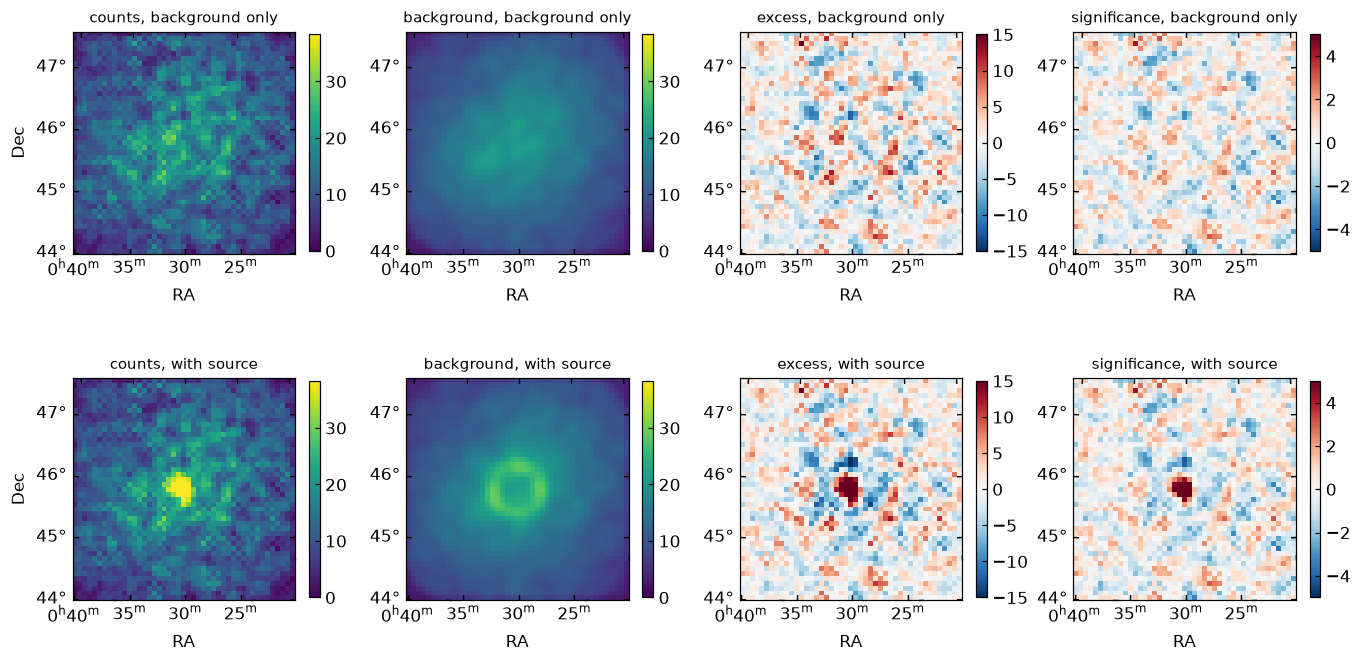

In [7]:
wcs = geom.to_image().wcs
titles = {"counts": "counts", "npred_background": "background", "npred_excess": "excess", "sqrt_ts": "significance"}
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5), subplot_kw={"projection": wcs})
for row, (m, label) in enumerate([(maps_bkg, "background only"), (maps_src, "with source")]):
    for col, k in enumerate(titles):
        ax = axes[row, col]
        if k == "sqrt_ts":
            im = ax.imshow(m[k], origin="lower", cmap="RdBu_r", vmin=-5, vmax=5)
        elif k == "npred_excess":
            im = ax.imshow(m[k], origin="lower", cmap="RdBu_r", vmin=-15, vmax=15)
        else:
            im = ax.imshow(m[k], origin="lower", vmin=0, vmax=np.nanmax(maps_src["npred_background"]) * 1.3)
        ax.set_title(f"{titles[k]}, {label}", fontsize=10)
        ax.coords[0].set_axislabel("RA")
        ax.coords[1].set_axislabel("Dec" if col == 0 else " ")
        fig.colorbar(im, ax=ax, shrink=0.75)
figs.save(fig, "maps")
plt.show()

Exposure of the stacked dataset at 1 TeV, and its profile through the target along RA. Each run contributes
out to the 2.5 deg offset-max cut, where its exposure is about a quarter of the central one at 1 TeV
(notebook 03); the map edges are 1.4 to 2.3 deg from the pointings, so the stacked exposure falls smoothly
towards them.

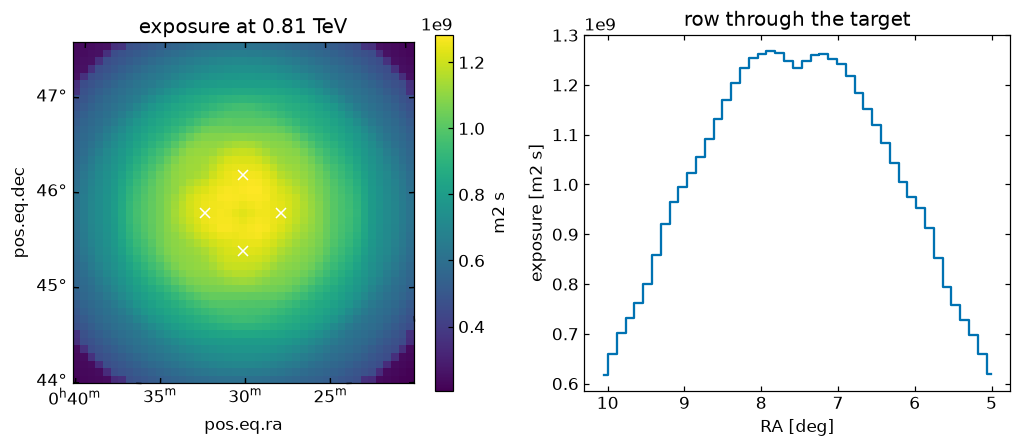

In [8]:
expo = red_bkg.stacked.exposure
e_idx = int(np.argmin(np.abs(expo.geom.axes["energy_true"].center.to_value(u.TeV) - 1)))
img = expo.data[e_idx]
fig = plt.figure(figsize=(11, 4.2))
ax = fig.add_subplot(1, 2, 1, projection=wcs)
im = ax.imshow(img, origin="lower")
pnt = pointings.coords(point)
ax.plot(pnt.ra.deg, pnt.dec.deg, "wx", transform=ax.get_transform("icrs"))
ax.set_title(f"exposure at {expo.geom.axes['energy_true'].center[e_idx]:.2f}")
fig.colorbar(im, ax=ax, label=f"{expo.unit}")
ax2 = fig.add_subplot(1, 2, 2)
iy = img.shape[0] // 2
ra = geom.to_image().get_coord().skycoord.ra.deg[iy]
ax2.plot(ra, img[iy], drawstyle="steps-mid")
ax2.set(xlabel="RA [deg]", ylabel=f"exposure [{expo.unit}]", title="row through the target")
ax2.invert_xaxis()
figs.save(fig, "exposure")
plt.show()

Significance distribution of the background-only dataset, over the exposed pixels (the whole map), for the reference ring
background and the two other methods of `from_dl3`: `model` (the background model of each run as it is, here
simulst's own model) and `fov` (that model scaled per run to the counts). Neighbouring pixels share counts
through the 0.1 deg top-hat, so the effective number of independent values is about five times smaller than the
number of pixels.

[cache] reduce/7a4d2deaf27f: computed and stored


[cache] reduce/6b71547df91d: computed and stored


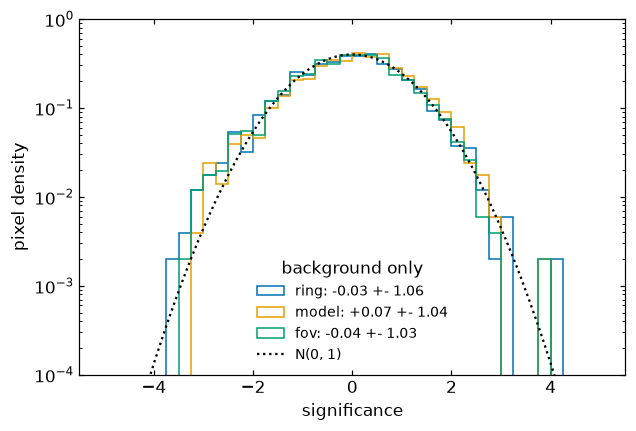

background,pixels,mean,std,counts,background counts,(n - b) / sqrt(b)
str5,int64,float64,float64,float64,float64,float64
ring,2025,-0.03256319354043595,1.0596254963445533,5023.0,5007.33935546875,0.2213125893022841
model,2025,0.06715545228937715,1.0358701897883484,5023.0,4863.34130859375,2.289418514893964
fov,2025,-0.04372368592476188,1.0304765862705731,5023.0,5022.99951171875,6.889512298337406e-06


In [9]:
reds = {"ring": red_bkg}
for method in ("model", "fov"):
    reds[method] = reduce.from_dl3(dl3_bkg, geom, T0, {"background": method})

x = np.linspace(-5, 5, 201)
bins = np.linspace(-5, 5, 41)
fig, ax = plt.subplots()
rows = []
for method, red in reds.items():
    sig = excess_maps(red.stacked)["sqrt_ts"][exposed]
    sig = sig[np.isfinite(sig)]
    ax.hist(sig, bins, histtype="step", density=True, label=f"{method}: {sig.mean():+.2f} +- {sig.std():.2f}")
    n, b = in_mask(red.stacked, red.stacked.counts), in_mask(red.stacked, red.stacked.npred_background())
    rows.append({"background": method, "pixels": sig.size, "mean": sig.mean(), "std": sig.std(),
                 "counts": n, "background counts": b, "(n - b) / sqrt(b)": (n - b) / np.sqrt(b)})
ax.plot(x, stats.norm.pdf(x), "k:", label="N(0, 1)")
ax.set(yscale="log", ylim=(1e-4, 1), xlabel="significance", ylabel="pixel density")
ax.legend(title="background only", fontsize=9)
figs.save(fig, "significance_distribution")
plt.show()
Table(rows=rows)

The same distribution for the dataset with source, excluding 0.4 deg around the source, and the significance at
the source position.

In [10]:
sep = geom.to_image().get_coord().skycoord.separation(TARGET).deg
sig = maps_src["sqrt_ts"]
away = exposed & (sep > 0.4) & np.isfinite(sig)
iy, ix = np.unravel_index(np.argmin(sep), sep.shape)
print(f"away from the source: mean {sig[away].mean():+.2f}, std {sig[away].std():.2f} over {away.sum()} pixels")
print(f"significance at the source pixel {sig[iy, ix]:.1f}, highest {np.nanmax(sig):.1f}; "
      f"excess {maps_src['npred_excess'][iy, ix]:.0f} counts in 0.1 deg")

away from the source: mean -0.09, std 1.08 over 1944 pixels
significance at the source pixel 14.4, highest 14.4; excess 97 counts in 0.1 deg


Flux of the source: a point source with a power-law spectrum at the injected position, amplitude and index
free, fitted to the stacked dataset with the background fixed. Position fixed, because the check is the flux
and the free-position fit on the ring dataset wanders off the map in the first iterations. Bins where the ring
holds no counts (a few high-energy bins) have a zero background estimate, which makes the Cash statistic
undefined wherever a count falls; they are left out of the fit (`mask_fit`). The fit is done on the reference
ring background, on the ring with a 0.4 deg exclusion circle around the source, and on the `model` and `fov`
backgrounds (the latter with the same exclusion).

In [11]:
def fit_source(ds):
    model = SkyModel(PowerLawSpectralModel(index=2.2, amplitude=5e-12 * u.Unit("cm-2 s-1 TeV-1"), reference=1 * u.TeV),
                     PointSpatialModel(lon_0=TARGET.ra, lat_0=TARGET.dec, frame="icrs"), name="src")
    model.spatial_model.parameters.freeze_all()
    ds = ds.copy(name="fit")
    ds.mask_fit = ds.mask_safe.copy()
    ds.mask_fit.data &= ds.background.data > 0
    ds.models = [model]
    result = Fit().run([ds])
    p = model.parameters
    return {"success": result.success, "amplitude": p["amplitude"].value, "amplitude err": p["amplitude"].error,
            "index": p["index"].value, "index err": p["index"].error}


exclude = {"exclusion": [[TARGET.ra.deg, TARGET.dec.deg, 0.4]]}
cases = {"ring": {}, "ring, source excluded": exclude, "model": {"background": "model"},
         "fov, source excluded": {"background": "fov", **exclude}}
rows = [{"background": "injected", "amplitude": SOURCE.amplitude, "index": SOURCE.index}]
for label, settings in cases.items():
    rows.append({"background": label, **fit_source(reduce.from_dl3(dl3_src, geom, T0, settings).stacked)})
fits_table = Table(rows=rows)
fits_table["amplitude / injected"] = fits_table["amplitude"] / SOURCE.amplitude
fits_table["amplitude"].format = fits_table["amplitude err"].format = ".3e"
for c in ("index", "index err", "amplitude / injected"):
    fits_table[c].format = ".3f"
fits_table

[cache] reduce/9543d085a43e: loaded


[cache] reduce/c21b0e1feb6c: computed and stored


[cache] reduce/0fec0794a010: computed and stored


[cache] reduce/bad0e63bfbf9: computed and stored


background,amplitude,index,success,amplitude err,index err,amplitude / injected
str21,float64,float64,bool,float64,float64,float64
injected,1.000e-11,2.000,--,--,--,1.000
ring,9.121e-12,2.000,True,1.106e-12,0.117,0.912
"ring, source excluded",1.005e-11,1.925,True,1.165e-12,0.115,1.005
model,1.043e-11,2.030,True,1.166e-12,0.109,1.043
"fov, source excluded",1.016e-11,2.018,True,1.156e-12,0.109,1.016


The four fits recover the injected flux within their statistical error (about 11 per cent here). The plain ring
estimate sits lowest, at 0.91 of the injected amplitude: pixels between 0.3 and 0.5 deg from the source have the
source inside their ring, so their background is overestimated and the fitted point-source tail is pulled down.
Excluding the source from the ring brings it to 1.00. For an unknown source position, as in the GW search, no
exclusion is possible, and the ring biases a recovered flux low by an amount of this order.

On the background-only data all three methods give a significance distribution with mean within 0.07 of zero
and width 1.03 to 1.06. With about 400 independent top-hat positions in the map, the width is known to about
0.035, so the ring (1.06) is at most marginally wider than N(0, 1). The ring estimate takes each pixel's
background from a ring of about 16 times the top-hat area, which adds about 3 per cent to the width through its
own Poisson noise; the Monte Carlo realisations, which fake counts on a fixed background map, do not include
that noise. simulst's own background model (`model`, the mid-run slice on the 0.25 deg library cells) predicts
3 per cent fewer counts than were simulated (2.3 sigma over the four runs), because the events are drawn per
2-minute slice from an upsampled version of it. `fov` absorbs that with one normalisation per run.

Outputs: the cached reductions `reduce/<key>` listed above and the
figures `maps`, `exposure`, `significance_distribution` in `outputs/figures/0_tools/04_reduce/`.